# Proyecto Hito 3 — Minería de Datos (Data Hunters)
## Detección de Descalce y Segmentación de Obras Públicas del Sistema Invierte.pe

**Integrantes:**
- Fernando Torres Valdivia
- Romy Tipacti Carrasco
- Arturo Álvarez de la Torre

**Docente:** Soledad Espezúa Llerena  
**Institución:** Universidad del Pacífico  
**Base de datos:** `matriz_analitica_final.csv` (2,067 proyectos CUI)

---

### Resumen del Hito 3: Revisión Metodológica e Implementación Inicial
En este hito consolidamos la fase de modelado y experimentación no supervisada para segmentar el portafolio de proyectos de inversión pública en ejecución activa:
1. **Representación final:** Definición estricta de la unidad de análisis (1 fila = 1 Proyecto CUI) con 12 variables analíticas estandarizadas (`StandardScaler`).
2. **K-Means (Particional):** Evaluación de inercia para $K \in [1, 7]$, selección de $K=4$ por método del codo y perfilamiento de clusters.
3. **DBSCAN (Densidad):** Calibración de $min\_samples=24$ y radio $\varepsilon=1.8$ mediante análisis de $k$-distancias, detectando regiones densas y un 8.4% de obras complejas como ruido.
4. **Clustering Jerárquico Aglomerativo:** Exploración de dendrogramas con método Ward y evaluación comparativa contra criterios de enlace `single`, `complete` y `average`.
5. **Comparación cruzada:** Validación de consistencia entre modelos, aislamiento de megaproyectos singulares (Línea 2 del Metro) y cruce con la alerta de gasto adelantado.
6. **Componente espacial (GeoPandas):** Distribución territorial de proyectos y análisis focalizado en la región de Cusco.


In [1]:
# Importamos las librerías necesarias para el flujo analítico completo
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

# Configuración visual para mantener coherencia en gráficos y tablas
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8.5, 4.5)
plt.rcParams["font.size"] = 10
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: "%.2f" % x)


## 1. Carga de datos y representación final

Cargamos la matriz analítica construida en el Hito 2. Cada registro representa una obra pública única identificada por su **Código Único de Inversión (CUI)**.

Seleccionamos las **12 variables clave** preparadas para distancias:
- **Ejecución y brecha:** `pct_ejecucion_financiera`, `avance_fisico_pct`, `brecha_gasto_avance`.
- **Dimensión económica:** `costo_inversion`, `gasto_total`, `gasto_anual_promedio`.
- **Maduración y contratos:** `tiempo_maduracion_anios`, `n_registros_presupuesto`, `n_contratos`, `tamano_inversion_ord`.
- **Nivel institucional:** `gob_GOBIERNOS LOCALES`, `gob_GOBIERNOS REGIONALES` (Gobierno Nacional como categoría base).

> **Aislamiento de variables:** Excluimos identificadores (`codigo_proyecto`) y la etiqueta de alerta `flag_gasto_adelantado` para no sesgar el cálculo de similitudes.


In [2]:
# Leemos la matriz analítica final
ruta_datos = "matriz_analitica_final.csv" if os.path.exists("matriz_analitica_final.csv") else "Entrega_3/matriz_analitica_final.csv"
df = pd.read_csv(ruta_datos)

features = [
    "pct_ejecucion_financiera",
    "avance_fisico_pct",
    "brecha_gasto_avance",
    "costo_inversion",
    "gasto_total",
    "tiempo_maduracion_anios",
    "gasto_anual_promedio",
    "n_registros_presupuesto",
    "n_contratos",
    "tamano_inversion_ord",
    "gob_GOBIERNOS LOCALES",
    "gob_GOBIERNOS REGIONALES"
]

X = df[features].copy()

# Estandarizamos con StandardScaler para nivelar magnitudes
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

# Inicializamos el DataFrame de resultados
df_resultados = df.copy()

print(f"Base cargada: {X_std.shape[0]:,} proyectos × {X_std.shape[1]} atributos de distancia")
display(df[["codigo_proyecto", "nombre_proyecto", "departamento", "costo_inversion", "avance_fisico_pct", "brecha_gasto_avance"]].head(3))


Base cargada: 2,067 proyectos × 12 atributos de distancia


,codigo_proyecto,nombre_proyecto,departamento,costo_inversion,avance_fisico_pct,brecha_gasto_avance
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,LIMA,263517133.53,100.00,-29.71
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,LIMA,269114681.55,100.00,-35.35
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,ANCASH,189747493.86,100.00,-63.39


## 2. Reducción dimensional para exploración visual (PCA)

Aplicamos Análisis de Componentes Principales (PCA) sobre la matriz estandarizada para proyectar el espacio de 12 dimensiones en un plano bidimensional ($Z_1, Z_2$). Esto nos permite inspeccionar la dispersión geométrica de los proyectos antes de aplicar los modelos de agrupamiento.


Varianza explicada en 2 componentes: 48.55%
  Componente 1 (Z1): 29.67%
  Componente 2 (Z2): 18.88%


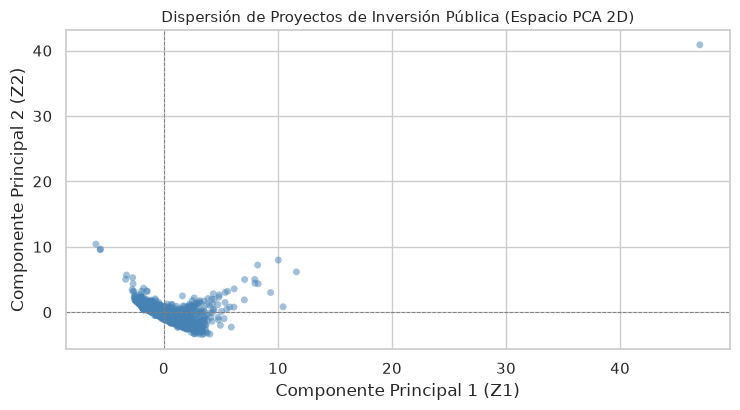

In [3]:
# Ajustamos PCA en 2 componentes para fines de visualización
pca = PCA(n_components=2, random_state=42)
Z_pca = pca.fit_transform(X_std)

print(f"Varianza explicada en 2 componentes: {pca.explained_variance_ratio_.sum() * 100:.2f}%")
print(f"  Componente 1 (Z1): {pca.explained_variance_ratio_[0] * 100:.2f}%")
print(f"  Componente 2 (Z2): {pca.explained_variance_ratio_[1] * 100:.2f}%")

plt.figure(figsize=(7.5, 4.2))
plt.scatter(Z_pca[:, 0], Z_pca[:, 1], alpha=0.5, s=25, color="steelblue", edgecolors="none")
plt.title("Dispersión de Proyectos de Inversión Pública (Espacio PCA 2D)", fontsize=11)
plt.xlabel("Componente Principal 1 (Z1)")
plt.ylabel("Componente Principal 2 (Z2)")
plt.axhline(0, color="gray", linestyle="--", linewidth=0.7)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.7)
plt.tight_layout()
plt.show()


## 3. Implementación y diseño experimental: K-Means

Evaluamos la técnica de agrupamiento particional **K-Means**, la cual asume clusters esféricos e intenta minimizar la inercia (suma de cuadrados intra-cluster):
1. Probamos valores de $K \in [1, 7]$ con inicialización `k-means++` y 10 reinicios aleatorios.
2. Identificamos el codo de inercia para seleccionar un número tentativo de grupos.
3. Ajustamos el modelo definitivo y analizamos el perfil de cada cluster.


Tabla de inercia según número de clusters (K):


,K,Inercia,Reducción,Reducción_%
0,1,24804.00,NaN,NaN
1,2,20711.38,4092.62,16.50
2,3,16628.09,4083.28,19.72
3,4,14893.49,1734.60,10.43
4,5,13484.85,1408.63,9.46
5,6,12034.53,1450.32,10.76
6,7,11005.94,1028.59,8.55


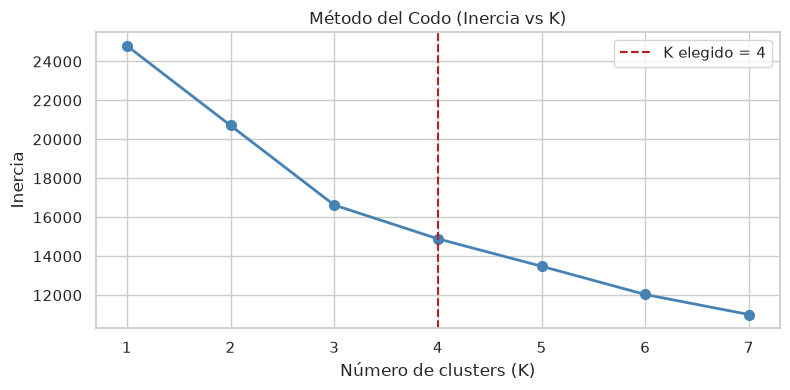

In [4]:
# Evaluación del método del codo
inercia_k = []
K_eval = range(1, 8)

for k in K_eval:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    km.fit(X_std)
    inercia_k.append(km.inertia_)

df_codo = pd.DataFrame({
    "K": list(K_eval),
    "Inercia": inercia_k
})
df_codo["Reducción"] = df_codo["Inercia"].diff().abs()
df_codo["Reducción_%"] = (df_codo["Reducción"] / df_codo["Inercia"].shift(1)) * 100

print("Tabla de inercia según número de clusters (K):")
display(df_codo.round(2))

# Gráfico del codo
plt.figure(figsize=(8, 4))
plt.plot(df_codo["K"], df_codo["Inercia"], marker="o", color="steelblue", linewidth=2, markersize=7)
plt.axvline(x=4, color="firebrick", linestyle="--", label="K elegido = 4")
plt.title("Método del Codo (Inercia vs K)", fontsize=12)
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inercia")
plt.legend()
plt.tight_layout()
plt.show()


In [5]:
# Ajustamos el modelo con K=4
k_elegido = 4
kmeans_final = KMeans(n_clusters=k_elegido, init="k-means++", n_init=10, random_state=42)
df_resultados["cluster_kmeans"] = kmeans_final.fit_predict(X_std)

print(f"Inercia con K={k_elegido}: {kmeans_final.inertia_:,.2f}")

# Perfil promedio de variables en unidades originales
perfil_km = df_resultados.groupby("cluster_kmeans")[features[:9]].mean().round(2)
tamanos_km = df_resultados["cluster_kmeans"].value_counts().sort_index().rename("n_proyectos")
pct_km = (df_resultados["cluster_kmeans"].value_counts(normalize=True).sort_index() * 100).round(2).rename("porcentaje_%")

resumen_km = pd.concat([tamanos_km, pct_km, perfil_km], axis=1)
print("\nPerfil promedio de clusters K-Means en unidades originales:")
display(resumen_km)


Inercia con K=4: 14,893.49

Perfil promedio de clusters K-Means en unidades originales:


,n_proyectos,porcentaje_%,pct_ejecucion_financiera,avance_fisico_pct,brecha_gasto_avance,costo_inversion,gasto_total,tiempo_maduracion_anios,gasto_anual_promedio,n_registros_presupuesto,n_contratos
cluster_kmeans,,,,,,,,,,,
0,809,39.14,53.66,78.30,-24.64,13676719.42,5861485.81,11.39,559618.85,13.53,132.11
1,1,0.05,15.22,50.42,-35.20,12075451952.74,1837811051.69,13.00,141370080.90,34.00,72.00
2,924,44.70,59.39,78.64,-19.25,5792761.65,2495449.02,9.34,270038.10,10.22,129.01
3,333,16.11,35.28,63.86,-28.58,168594086.08,53343289.60,14.14,3926052.42,24.69,362.79


## 4. Implementación y diseño experimental: DBSCAN

DBSCAN identifica agrupamientos conectando regiones densas de puntos y clasificando las observaciones aisladas como ruido (`-1`), sin asumir formas esféricas ni fijar $K$ de antemano:
- **`min_samples`:** Fijamos $\text{min\_samples} = 24$ (el doble de las 12 dimensiones) para evitar que pequeñas fluctuaciones generen micro-clusters falsos.
- **`eps` ($\varepsilon$):** Construimos la curva de 24-distancias para ubicar el codo de densidad e inspeccionar la sensibilidad ante valores cercanos.


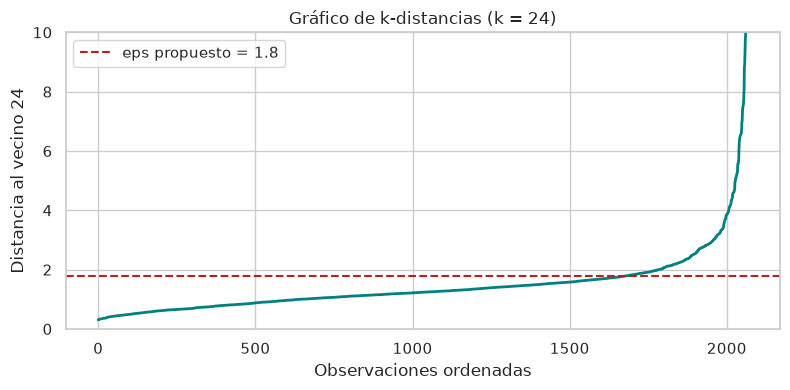

Sensibilidad de DBSCAN según radio eps:


,eps,n_clusters,ruido_%,n_ruido
0,1.50,3,14.08,291
1,1.80,3,8.42,174
2,2.00,3,6.34,131
3,2.20,2,5.42,112


In [6]:
# Gráfico de 24-distancias ordenadas
min_samples = 24
vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_std)
distancias, _ = vecinos.kneighbors(X_std)
k_dist = np.sort(distancias[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(np.arange(len(k_dist)), k_dist, color="teal", linewidth=2)
plt.axhline(1.8, color="firebrick", linestyle="--", label="eps propuesto = 1.8")
plt.title(f"Gráfico de k-distancias (k = {min_samples})", fontsize=12)
plt.xlabel("Observaciones ordenadas")
plt.ylabel(f"Distancia al vecino {min_samples}")
plt.ylim(0, 10)
plt.legend()
plt.tight_layout()
plt.show()

# Evaluación de sensibilidad para valores cercanos de eps
comparacion_eps = []
for eps in [1.5, 1.8, 2.0, 2.2]:
    modelo = DBSCAN(eps=eps, min_samples=min_samples)
    labels = modelo.fit_predict(X_std)
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    pct_r = np.mean(labels == -1) * 100
    comparacion_eps.append({
        "eps": eps,
        "n_clusters": n_cl,
        "ruido_%": pct_r,
        "n_ruido": np.sum(labels == -1)
    })

print("Sensibilidad de DBSCAN según radio eps:")
display(pd.DataFrame(comparacion_eps).round(2))


In [7]:
# Ajustamos la partición final de DBSCAN con eps=1.8
eps_elegido = 1.8
dbscan_final = DBSCAN(eps=eps_elegido, min_samples=min_samples)
df_resultados["cluster_dbscan"] = dbscan_final.fit_predict(X_std)

conteos_db = df_resultados["cluster_dbscan"].value_counts().sort_index().to_frame("n_proyectos")
conteos_db["porcentaje_%"] = (df_resultados["cluster_dbscan"].value_counts(normalize=True).sort_index() * 100).round(2)
print("Distribución de observaciones en DBSCAN (eps=1.8, min_samples=24):")
display(conteos_db)


Distribución de observaciones en DBSCAN (eps=1.8, min_samples=24):


,n_proyectos,porcentaje_%
cluster_dbscan,,
-1,174,8.42
0,501,24.24
1,482,23.32
2,910,44.03


## 5. Implementación y diseño experimental: Clustering Jerárquico

El clustering jerárquico aglomerativo genera un árbol de fusiones paso a paso. Para analizar su comportamiento:
1. Graficamos un **dendrograma** sobre una muestra reproducible de 50 proyectos para inspeccionar la altura de las fusiones sin que las etiquetas se solapen.
2. Comparamos los 4 criterios de enlace clásicos (`single`, `complete`, `average` y `ward`) fijando 4 clusters para verificar balance y sensibilidad a valores extremos.


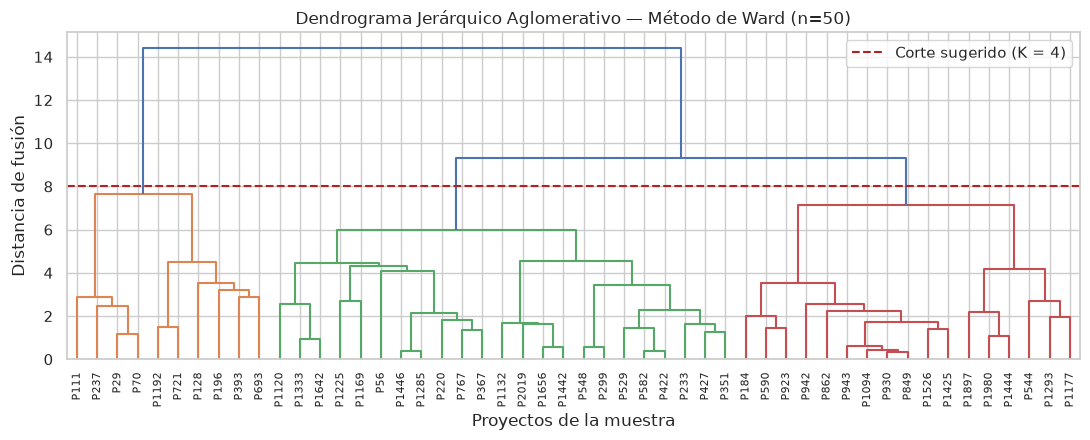

Comparación de criterios de enlace jerárquico para K=4:


,linkage,n_clusters,tamaño_min,tamaño_max
0,single,4,1,2062
1,complete,4,1,2053
2,average,4,1,2054
3,ward,4,1,1117


In [8]:
# Dendrograma en muestra reproducible de 50 proyectos
np.random.seed(42)
indices_muestra = np.random.choice(len(df), size=50, replace=False)
X_muestra = X_std[indices_muestra]
Z_ward_muestra = linkage(X_muestra, method="ward")

plt.figure(figsize=(11, 4.5))
dendrogram(
    Z_ward_muestra,
    labels=[f"P{i}" for i in indices_muestra],
    leaf_rotation=90,
    leaf_font_size=8,
    color_threshold=8.0
)
plt.axhline(y=8.0, color="firebrick", linestyle="--", label="Corte sugerido (K = 4)")
plt.title("Dendrograma Jerárquico Aglomerativo — Método de Ward (n=50)", fontsize=12)
plt.xlabel("Proyectos de la muestra")
plt.ylabel("Distancia de fusión")
plt.legend()
plt.tight_layout()
plt.show()

# Comparación de criterios de enlace para K=4
resumen_linkage = []
for metodo in ["single", "complete", "average", "ward"]:
    modelo_h = AgglomerativeClustering(n_clusters=4, linkage=metodo)
    labels = modelo_h.fit_predict(X_std)
    conteos = pd.Series(labels).value_counts()
    resumen_linkage.append({
        "linkage": metodo,
        "n_clusters": len(conteos),
        "tamaño_min": conteos.min(),
        "tamaño_max": conteos.max()
    })

print("Comparación de criterios de enlace jerárquico para K=4:")
display(pd.DataFrame(resumen_linkage))


In [9]:
# Ajustamos la partición definitiva con método Ward y K=4
hier_final = AgglomerativeClustering(n_clusters=4, linkage="ward")
df_resultados["cluster_hier"] = hier_final.fit_predict(X_std)

conteos_hier = df_resultados["cluster_hier"].value_counts().sort_index().to_frame("n_proyectos")
conteos_hier["porcentaje_%"] = (df_resultados["cluster_hier"].value_counts(normalize=True).sort_index() * 100).round(2)
print("Distribución de proyectos en Clustering Jerárquico (Ward, K=4):")
display(conteos_hier)


Distribución de proyectos en Clustering Jerárquico (Ward, K=4):


,n_proyectos,porcentaje_%
cluster_hier,,
0,405,19.59
1,1117,54.04
2,544,26.32
3,1,0.05


## 6. Comparación global de soluciones y validación cruzada

Contrastamos las tres estructuras encontradas mediante tablas de contingencia y visualización en el plano PCA:
- **K-Means vs Jerárquico Ward:** Observamos alta concordancia en los grupos principales y aislamiento unánime del proyecto singular (Línea 2 del Metro).
- **DBSCAN vs K-Means:** Verificamos qué proyectos fueron catalogados como ruido (`-1`), confirmando que corresponden a obras complejas y dispersas.
- **Cruce con alerta de negocio:** Evaluamos la tasa de proyectos con alerta crítica (`flag_gasto_adelantado`) en cada cluster.


In [10]:
# 1. Contingencia K-Means vs Jerárquico Ward
print("1. Tabla de contingencia: K-Means vs Jerárquico Ward:")
display(pd.crosstab(df_resultados["cluster_kmeans"], df_resultados["cluster_hier"], rownames=["K-Means"], colnames=["Jerárquico Ward"]))

# 2. Contingencia DBSCAN vs K-Means
print("\n2. Tabla de contingencia: DBSCAN vs K-Means:")
display(pd.crosstab(df_resultados["cluster_dbscan"], df_resultados["cluster_kmeans"], rownames=["DBSCAN"], colnames=["K-Means"]))

# 3. Tasa de proyectos con alerta de gasto adelantado por cluster de K-Means
cruce_alerta = pd.crosstab(
    df_resultados["cluster_kmeans"],
    df_resultados["flag_gasto_adelantado"].map({0: "Sin alerta", 1: "Con alerta"}),
    normalize="index"
) * 100
print("\n3. Porcentaje de proyectos con alerta de gasto adelantado por cluster (%):")
display(cruce_alerta.round(2))


1. Tabla de contingencia: K-Means vs Jerárquico Ward:


Jerárquico Ward,0,1,2,3
K-Means,,,,
0,143,358,308,0
1,0,0,0,1
2,190,725,9,0
3,72,34,227,0



2. Tabla de contingencia: DBSCAN vs K-Means:


K-Means,0,1,2,3
DBSCAN,,,,
-1,21,1,31,121
0,445,0,6,50
1,343,0,0,139
2,0,0,887,23



3. Porcentaje de proyectos con alerta de gasto adelantado por cluster (%):


flag_gasto_adelantado,Con alerta,Sin alerta
cluster_kmeans,,
0,12.61,87.39
1,0.00,100.00
2,14.18,85.82
3,14.71,85.29


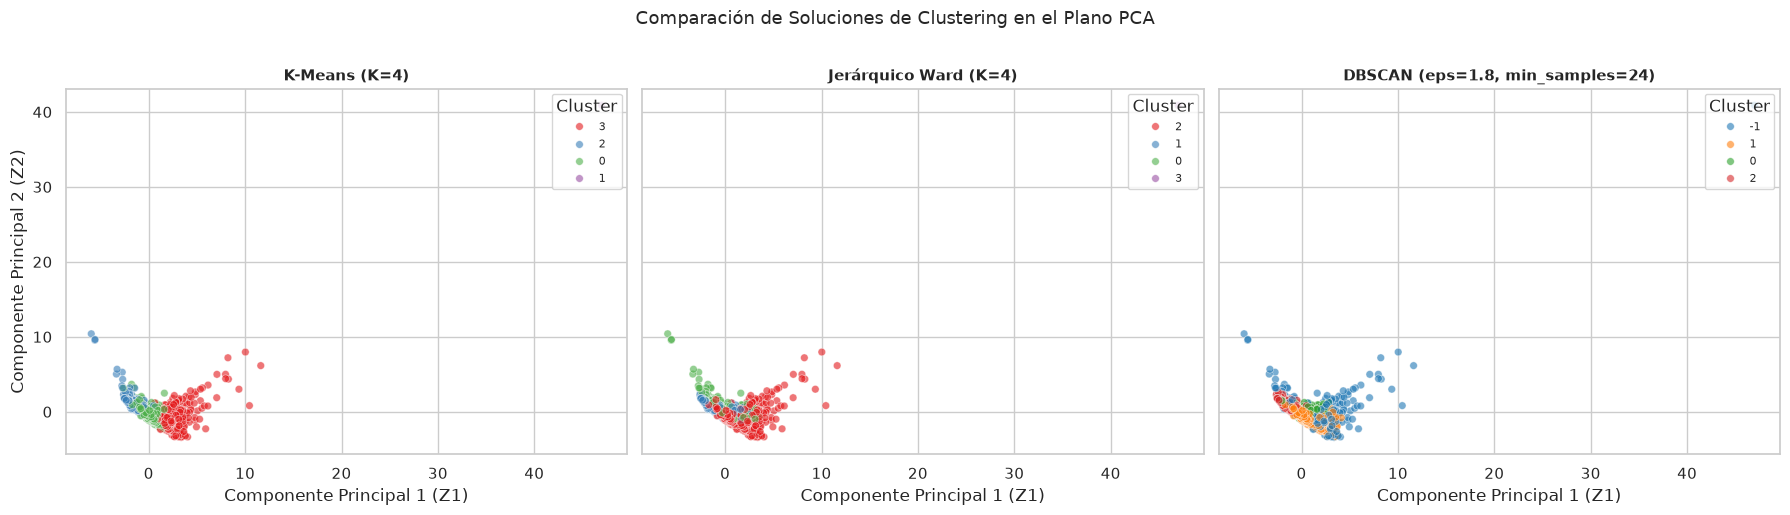

In [11]:
# Visualizamos las tres particiones lado a lado en el espacio PCA 2D
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)

modelos = [
    ("cluster_kmeans", "K-Means (K=4)", "Set1"),
    ("cluster_hier", "Jerárquico Ward (K=4)", "Set1"),
    ("cluster_dbscan", "DBSCAN (eps=1.8, min_samples=24)", "tab10")
]

for i, (col, titulo, paleta) in enumerate(modelos):
    ax = axes[i]
    viz_df = pd.DataFrame({
        "Z1": Z_pca[:, 0],
        "Z2": Z_pca[:, 1],
        "cluster": df_resultados[col].astype(str)
    })
    sns.scatterplot(
        data=viz_df, x="Z1", y="Z2", hue="cluster",
        palette=paleta, alpha=0.6, s=30, ax=ax
    )
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_xlabel("Componente Principal 1 (Z1)")
    if i == 0:
        ax.set_ylabel("Componente Principal 2 (Z2)")
    ax.legend(title="Cluster", loc="upper right", fontsize=8)

plt.suptitle("Comparación de Soluciones de Clustering en el Plano PCA", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()


## 7. Componente espacial y distribución territorial (GeoPandas)

Aprovechando la columna `departamento` de la matriz analítica, cruzamos los datos con los shapefiles oficiales del IGN para evaluar la distribución territorial de los proyectos de inversión y analizar las provincias de la región de mayor presencia fuera de Lima (**Cusco**, con 289 proyectos).


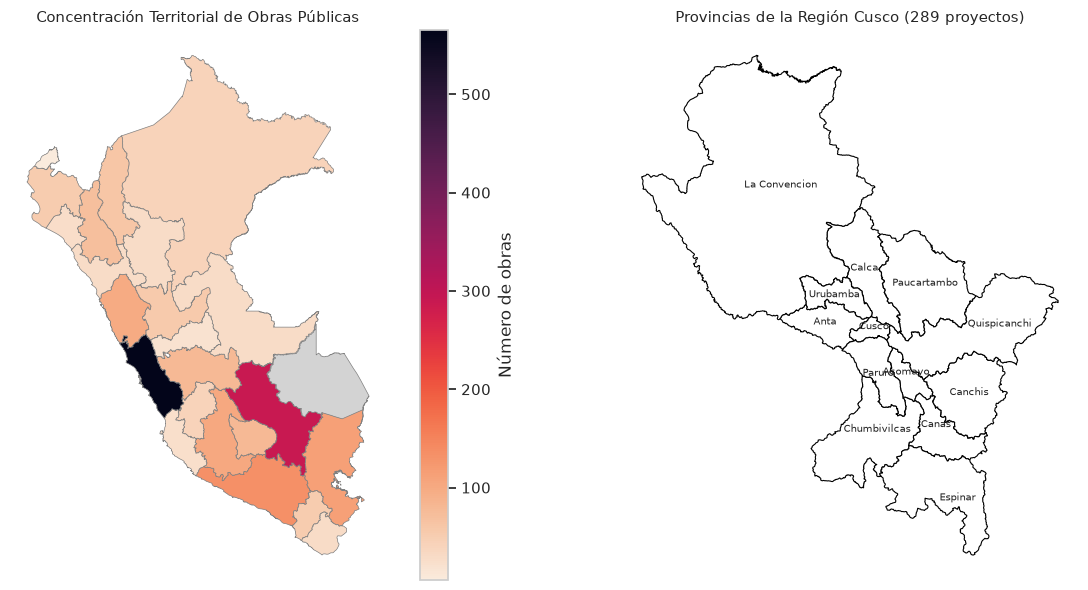

In [12]:
ruta_shapes = "peru_shapes" if os.path.exists("peru_shapes") else "Entrega_3/peru_shapes"

if os.path.exists(os.path.join(ruta_shapes, "per_admbnda_adm1_ign_20200714.shp")):
    regiones = gpd.read_file(os.path.join(ruta_shapes, "per_admbnda_adm1_ign_20200714.shp"))
    provincias = gpd.read_file(os.path.join(ruta_shapes, "per_admbnda_adm2_ign_20200714.shp"))
    
    # Conteo por región
    conteo_dep = (
        df_resultados["departamento"]
        .str.strip().str.title()
        .replace({"Provincia Constitucional Del Callao": "Callao"})
        .value_counts().reset_index()
    )
    conteo_dep.columns = ["ADM1_ES", "n_proyectos"]
    conteo_dep = conteo_dep[conteo_dep["ADM1_ES"] != ""]
    
    mapa_proyectos = regiones.merge(conteo_dep, on="ADM1_ES", how="left")
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Mapa nacional coroplético
    mapa_proyectos.plot(
        column="n_proyectos", cmap="rocket_r", edgecolor="gray", linewidth=0.5,
        legend=True, legend_kwds={"label": "Número de obras"}, missing_kwds={"color": "lightgray"},
        ax=ax1
    )
    ax1.set_title("Concentración Territorial de Obras Públicas", fontsize=11)
    ax1.set_axis_off()
    
    # Mapa de provincias de Cusco
    prov_cusco = provincias[provincias["ADM1_ES"] == "Cusco"].copy()
    prov_cusco.plot(ax=ax2, facecolor="white", edgecolor="black", linewidth=0.8)
    for idx, row in prov_cusco.iterrows():
        coords = row["geometry"].representative_point().coords[0]
        ax2.annotate(text=row["ADM2_ES"], xy=coords, horizontalalignment="center", fontsize=7, color="#222222")
    ax2.set_title("Provincias de la Región Cusco (289 proyectos)", fontsize=11)
    ax2.set_axis_off()
    
    plt.tight_layout()
    plt.show()
else:
    print("Shapefiles no encontrados en la ruta local.")


## 8. Guardado de la matriz analítica y trabajo pendiente para el Hito 4

### Hallazgos de la implementación inicial:
1. **Consistencia de estructura:** K-Means y Jerárquico Ward concuerdan ampliamente en separar obras de escala municipal de aquellas de alcance regional/nacional, y ambos identifican como cluster unitario a la Línea 2 del Metro de Lima.
2. **Detección de ruido con DBSCAN:** DBSCAN demostró que las obras no están distribuidas en esferas compactas ideales, sino que siguen densidades institucionales, clasificando al 8.4% como ruido (obras con plazos atípicos o descalces severos).
3. **Limitación de enlaces simples:** Los criterios `single`, `complete` y `average` resultaron inapropiados para este problema por sufrir de encadenamiento ante outliers.

### Trabajo pendiente para el Hito 4:
- Evaluación cuantitativa mediante métricas de validación interna: **Coeficiente de Silhouette** e **Índice de Davies-Bouldin** para todos los modelos.
- Perfilamiento estadístico exhaustivo de cada cluster con cruce de flags de riesgo fiscal para generar recomendaciones directas a la Contraloría General de la República.
- Consolidación del informe final del proyecto.


In [13]:
# Verificamos que las 3 etiquetas de clustering estén integradas en la matriz
columnas_guardar = ["cluster_kmeans", "cluster_dbscan", "cluster_hier"]
assert all(c in df_resultados.columns for c in columnas_guardar), "Faltan columnas de cluster"

# Guardamos la matriz analítica enriquecida para las siguientes fases
ruta_salida = "matriz_analitica_con_clusters.csv" if os.path.exists("matriz_analitica_con_clusters.csv") else "Entrega_3/matriz_analitica_con_clusters.csv"
df_resultados.to_csv(ruta_salida, index=False)

print(f"Matriz analítica actualizada guardada exitosamente en '{ruta_salida}'")
print(f"Dimensiones finales: {df_resultados.shape[0]:,} proyectos × {df_resultados.shape[1]} columnas")
display(df_resultados[["codigo_proyecto", "nombre_proyecto", "departamento", "cluster_kmeans", "cluster_dbscan", "cluster_hier"]].head(5))


Matriz analítica actualizada guardada exitosamente en 'matriz_analitica_con_clusters.csv'
Dimensiones finales: 2,067 proyectos × 20 columnas


,codigo_proyecto,nombre_proyecto,departamento,cluster_kmeans,cluster_dbscan,cluster_hier
0,2002060,REHABILITACION Y MEJORAMIENTO DE CARRETERA TIN...,LIMA,3,-1,2
1,2002210,REHABILITACION Y MEJORAMIENTO DE LA CARRETERA ...,LIMA,3,-1,2
2,2002604,REHABILITACION DE LA CARRETERA CASMA-HUARAZ,ANCASH,3,1,2
3,2015918,PROYECTO VIAL TACNA LA PAZ,TACNA,3,-1,2
4,2017383,MEJORAMIENTO Y AMPLIACION DE LOS SISTEMAS DE A...,JUNIN,3,1,2
